# E1 Tecnicas avanzadas - Sign Language MNIST
-Carlos Navarrete\
-Sebastian Aravena



# **Introducción**

El lenguaje de señas es una de las principales formas de comunicación de las personas sordas, pero su desconocimiento por parte de la población oyente genera barreras en situaciones cotidianas. Este proyecto busca abordar este problema mediante Machine Learning, para así ingresarlo en el sistema educacional y promoverlo a ayudar a los más jovenes para que así estén más familiarizados con el lenguaje de señas y abrirles las puertas a futuro a que se interesen por aprenderlo.

Se utiliza el dataset Sign Language MNIST, compuesto por imágenes de 28×28 píxeles en escala de grises. Para este trabajo se seleccionaron únicamente las 5 vocales **(A, E, I, O, U)**, con el objetivo de realizar un problema más acotado y facilitar un análisis detallado de los errores y confusiones entre clases.

El objetivo es implementar un Perceptrón Multicapa **(MLP)** capaz de identificar la vocal representada en una imagen y evaluar su desempeño mediante métricas de clasificación.

# 1. Configuración Inicial y Carga de Datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import os
import random

from time import time
from tensorflow import keras
from keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

np.random.seed(29)
tf.random.set_seed(29)
random.seed(29)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


Se importan las librerías necesarias para manipulación de datos (`numpy`, `pandas`), visualización (`matplotlib`), construcción del modelo (`tensorflow`/`keras`) y evaluación (`sklearn.metrics`). Se fija una semilla (`seed = 29`) en todas las fuentes de aleatoriedad para que los resultados sean reproducibles.

In [2]:
# Rutas de los archivos adjuntos
TRAIN_CSV = "/content/sign_mnist_train.csv"
TEST_CSV = "/content/sign_mnist_test.csv"


if not os.path.exists(TRAIN_CSV):
    TRAIN_CSV = "sign_mnist_train.csv"
if not os.path.exists(TEST_CSV):
    TEST_CSV = "sign_mnist_test.csv"

print("Training CSV:", TRAIN_CSV)
print("Testing CSV:", TEST_CSV)

Training CSV: /content/sign_mnist_train.csv
Testing CSV: /content/sign_mnist_test.csv


In [4]:
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Dimensiones train:", train_df.shape)
print("Dimensiones test:", test_df.shape)
print("Columnas iniciales:", train_df.columns[:6].tolist())
print("Columnas finales:", train_df.columns[-5:].tolist())

Dimensiones train: (27455, 785)
Dimensiones test: (7172, 785)
Columnas iniciales: ['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5']
Columnas finales: ['pixel780', 'pixel781', 'pixel782', 'pixel783', 'pixel784']


# 2. Preprocesamiento de Datos: Filtrado y Remapeo

Selección exclusiva de las vocales

En Sign Language MNIST, las etiquetas numéricas correspondientes a las vocales requeridas son: **A=0, E=4, I=8, O=14, U=20**.

Se filtran ambos CSV antes de entrenar o evaluar el modelo. Después se remapean las etiquetas a `0..4` para que la salida de la red tenga exactamente cinco neuronas.

In [5]:
# Etiquetas originales para las vocales
VOWEL_LABELS = {
    0: "A",
    4: "E",
    8: "I",
    14: "O",
    20: "U"
}

VOWEL_ORDER = ["A", "E", "I", "O", "U"]
LABEL_TO_INDEX = {label: idx for idx, label in enumerate(sorted(VOWEL_LABELS))}
ORIGINAL_TO_INDEX = {original: idx for idx, original in enumerate([0, 4, 8, 14, 20])}

print("Mapeo etiqueta original -> vocal:", VOWEL_LABELS)
print("Mapeo etiqueta original -> índice del modelo:", ORIGINAL_TO_INDEX)

Mapeo etiqueta original -> vocal: {0: 'A', 4: 'E', 8: 'I', 14: 'O', 20: 'U'}
Mapeo etiqueta original -> índice del modelo: {0: 0, 4: 1, 8: 2, 14: 3, 20: 4}


In [6]:
# Comprobar etiquetas presentes en cada archivo
print("Etiquetas train antes del filtro:", sorted(train_df["label"].unique()))
print("Etiquetas test antes del filtro:", sorted(test_df["label"].unique()))

Etiquetas train antes del filtro: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
Etiquetas test antes del filtro: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]


In [7]:
# Filtrar exclusivamente A, E, I, O y U
train_vowels = train_df[train_df["label"].isin(VOWEL_LABELS.keys())].copy()
test_vowels = test_df[test_df["label"].isin(VOWEL_LABELS.keys())].copy()

# Remapear a índices consecutivos 0..4
train_vowels["target"] = train_vowels["label"].map(ORIGINAL_TO_INDEX)
test_vowels["target"] = test_vowels["label"].map(ORIGINAL_TO_INDEX)

print("Muestras train solo vocales:", len(train_vowels))
print("Muestras test solo vocales:", len(test_vowels))
print("Etiquetas finales train:", sorted(train_vowels["target"].unique()))
print("Etiquetas finales test:", sorted(test_vowels["target"].unique()))

Muestras train solo vocales: 5602
Muestras test solo vocales: 1629
Etiquetas finales train: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Etiquetas finales test: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [8]:
train_counts = train_vowels["label"].value_counts().sort_index()
test_counts = test_vowels["label"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Class": [VOWEL_LABELS[k] for k in [0, 4, 8, 14, 20]],
    "Original label": [0, 4, 8, 14, 20],
    "Training": [train_counts.get(k, 0) for k in [0, 4, 8, 14, 20]],
    "Testing": [test_counts.get(k, 0) for k in [0, 4, 8, 14, 20]]
})

class_distribution

,Class,Original label,Training,Testing
0,A,0,1126,331
1,E,4,957,498
2,I,8,1162,288
3,O,14,1196,246
4,U,20,1161,266


La tabla muestra cuántas imágenes hay por vocal en entrenamiento y test. Se observa que las clases están razonablemente balanceadas (entre 950 y 1.200 imágenes por vocal en entrenamiento), lo que evita que el modelo se sesgue hacia una clase por simple desbalance de datos.


# 3. Análisis Exploratorio de Datos

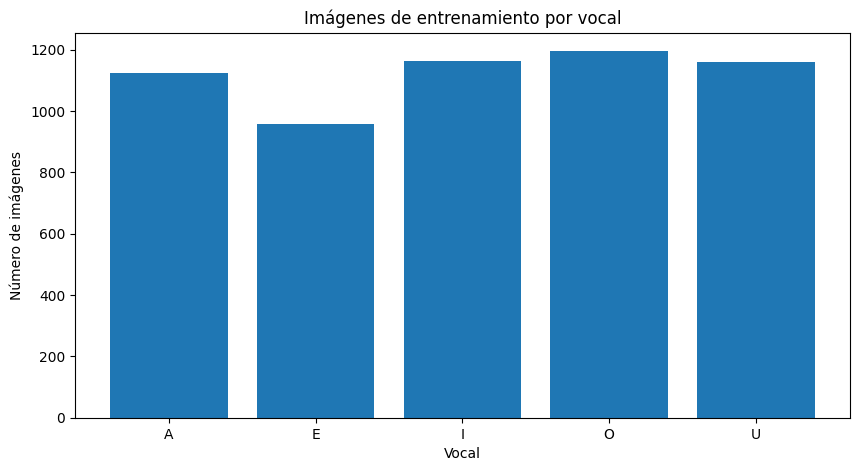

In [9]:
plt.figure(figsize=(10, 5))
plt.bar(class_distribution["Class"], class_distribution["Training"])
plt.title("Imágenes de entrenamiento por vocal")
plt.xlabel("Vocal")
plt.ylabel("Número de imágenes")
plt.show()

### Distribución de clases en entrenamiento

Se construye un gráfico de barras (plt.bar) usando la tabla class_distribution, donde el eje X son las 5 vocales y el eje Y es la cantidad de imágenes de entrenamiento disponibles para cada una.

Así permite detectar visualmente si hay un desbalance de clases. Si una vocal tuviera muchas menos imágenes que las demás, el modelo tendería a "aprender menos" esa clase y a predecirla peor. Como se ve en el gráfico, las 5 barras tienen una altura similar (entre 950 y 1.200 imágenes), lo que confirma que el dataset filtrado está razonablemente balanceado y no es necesario aplicar técnicas de balanceo antes de entrenar.

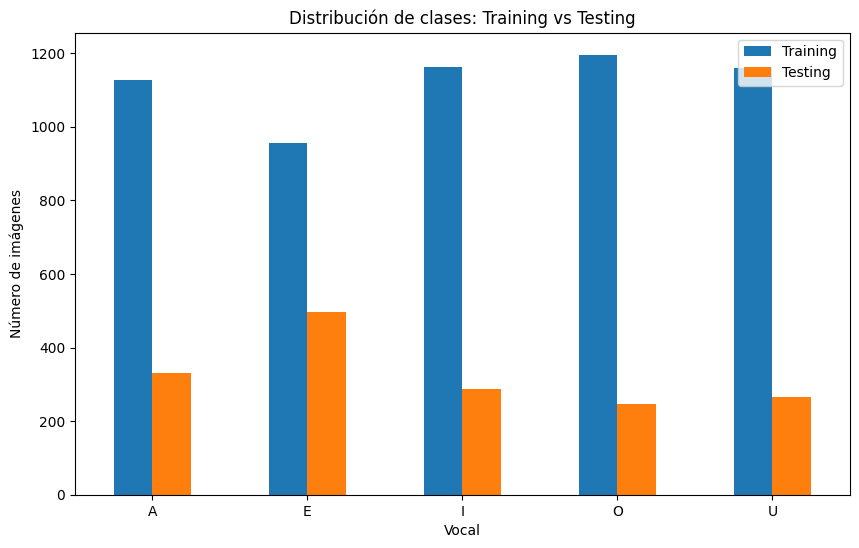

In [10]:
class_distribution.set_index("Class")[["Training", "Testing"]].plot(
    kind="bar", figsize=(10, 6)
)
plt.title("Distribución de clases: Training vs Testing")
plt.xlabel("Vocal")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=0)
plt.show()

### Comparación de distribución entre training y testing

**Qué hace el código:** toma la misma tabla `class_distribution`, pero ahora grafica dos barras por vocal, una para train y otra para test (`.plot(kind="bar")`), permitiendo comparar ambos conjuntos lado a lado.

**Para qué sirve:** verificar que la partición train/test mantiene proporciones similares entre clases. Esto es clave para que la evaluación final sea justa: si el test tuviera una proporción de clases muy distinta al train, el accuracy final no reflejaría bien qué tan bueno es realmente el modelo. Al ver que ambas barras siguen un patrón parecido por vocal, se confirma que la comparación de desempeño en test es representativa.

# 4. Preparación de Características (X) y Etiquetas (Y)

Preparación de las imágenes

Los CSV contienen una columna `label` y 784 columnas (`pixel1` ... `pixel784`). Se reconstruye cada fila como una imagen **28×28×1** y se normalizan los valores de píxel al rango `[0, 1]`.

In [11]:
PIXEL_COLUMNS = [f"pixel{i}" for i in range(1, 785)]
IMG_SHAPE = (28, 28, 1)
BATCH_SIZE = 32
SEED = 29
NUM_CLASSES = 5

X = train_vowels[PIXEL_COLUMNS].to_numpy(dtype="float32").reshape(-1, 28, 28, 1) / 255.0
y = train_vowels["target"].to_numpy(dtype="int32")

X_test = test_vowels[PIXEL_COLUMNS].to_numpy(dtype="float32").reshape(-1, 28, 28, 1) / 255.0
y_test = test_vowels["target"].to_numpy(dtype="int32")

print("X:", X.shape, "y:", y.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

X: (5602, 28, 28, 1) y: (5602,)
X_test: (1629, 28, 28, 1) y_test: (1629,)


In [12]:
# Separar validación desde el conjunto de entrenamiento. (TEST quedara reservado para la evaluación final)
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
    shuffle=True
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (4481, 28, 28, 1) (4481,)
Validation: (1121, 28, 28, 1) (1121,)
Test: (1629, 28, 28, 1) (1629,)


In [13]:
class_names = VOWEL_ORDER
print("Clases del modelo:", class_names)
print("Número de clases:", NUM_CLASSES)

Clases del modelo: ['A', 'E', 'I', 'O', 'U']
Número de clases: 5


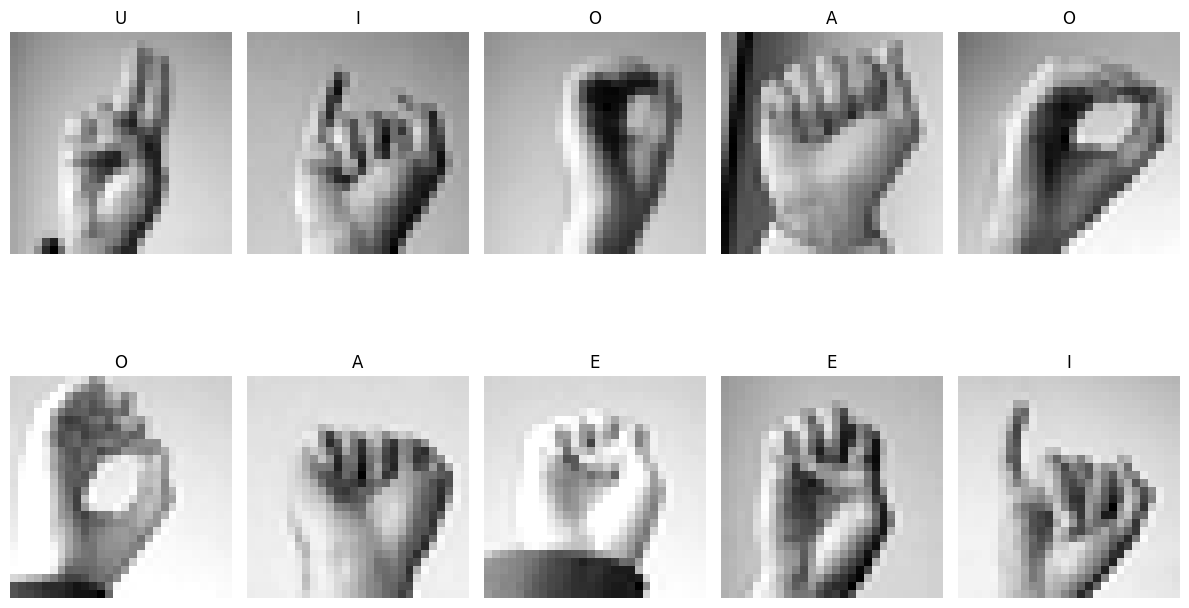

In [14]:
plt.figure(figsize=(12, 8))
indices = np.random.choice(len(X_train), size=10, replace=False)

for pos, idx in enumerate(indices, start=1):
    plt.subplot(2, 5, pos)
    plt.imshow(X_train[idx].squeeze(), cmap="gray")
    plt.title(class_names[y_train[idx]])
    plt.axis("off")

plt.tight_layout()
plt.show()

### Muestra de imágenes del set de entrenamiento

Se seleccionan 10 índices aleatorios (np.random.choice) del conjunto de entrenamiento y se muestran esas imágenes en una grilla de 2x5 (plt.subplot), cada una con su etiqueta real como título.

Es una verificación visual, no numérica, de que el preprocesamiento se hizo bien: que el reshape de 784 píxeles a una imagen 28×28 quedó correcto (si estuviera mal, se verían imágenes distorsionadas o "ruido"), y que la etiqueta mostrada corresponde efectivamente a la seña de la imagen. También permite mostrar cómo se ven realmente las señas de A, E, I, O, U y notar a simple vista que algunas (como I, O, U) tienen formas de mano parecidas, algo que luego se conecta con los errores del modelo.

In [15]:
print(f"Shape de una imagen: {X_train[0].shape}")
print(f"Rango de píxeles: [{X_train.min():.3f}, {X_train.max():.3f}]")
print(f"Shape de y_train: {y_train.shape}")

Shape de una imagen: (28, 28, 1)
Rango de píxeles: [0.000, 1.000]
Shape de y_train: (4481,)


# 5. Arquitectura del Modelo (MLP)

Se define una red neuronal Perceptrón Multicapa (MLP) adecuada para clasificar exclusivamente las cinco vocales A, E, I, O y U. La arquitectura, funciones de activación, función de pérdida, optimizador e hiperparámetros quedan documentados antes del entrenamiento.


Red neuronal

Se conserva la idea de la red del desarrollo original —Flatten + dos capas densas—, pero se adapta la entrada a las imágenes 28×28 en escala de grises y la salida a 5 clases.

In [16]:
red = keras.Sequential(name="RedE1_SignLanguage_Vocales")
red.add(keras.Input(shape=IMG_SHAPE))
red.add(keras.layers.Flatten())
red.add(keras.layers.Dense(128, activation="relu", name="primera_capa"))
red.add(keras.layers.Dense(64, activation="relu", name="segunda_capa"))
red.add(keras.layers.Dense(NUM_CLASSES, activation="softmax", name="capa_de_salida"))

red.summary()

Model: "RedE1_SignLanguage_Vocales"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ primera_capa (Dense)            │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ segunda_capa (Dense)            │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_de_salida (Dense)          │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,061 (426.02 KB)

 Trainable params: 109,061 (426.02 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
red.compile(
    loss="categorical_crossentropy",
    optimizer="sgd",
    metrics=["accuracy"]
)

In [18]:
# One-hot encoding de las cinco clases
y_train_one_hot = to_categorical(y_train, num_classes=NUM_CLASSES)
y_val_one_hot = to_categorical(y_val, num_classes=NUM_CLASSES)
y_test_one_hot = to_categorical(y_test, num_classes=NUM_CLASSES)

print("X_train:", X_train.shape)
print("y_train one-hot:", y_train_one_hot.shape)

X_train: (4481, 28, 28, 1)
y_train one-hot: (4481, 5)


# 6. Entrenamiento y Curvas

Se utiliza el conjunto de validación derivado de `train` para controlar el desempeño durante el entrenamiento. El CSV de `test` no participa en el ajuste de los pesos.

In [19]:
start_time = time()

h = red.fit(
    X_train,
    y_train_one_hot,
    epochs=10,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val_one_hot),
    verbose=1
)

end_time = time()
print("Tiempo de entrenamiento: %0.10f segundos" % (end_time - start_time))

Epoch 1/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4983 - loss: 1.4091 - val_accuracy: 0.2917 - val_loss: 1.4774
Epoch 2/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7427 - loss: 0.9609 - val_accuracy: 0.5076 - val_loss: 1.1767
Epoch 3/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8489 - loss: 0.6311 - val_accuracy: 0.6789 - val_loss: 0.7631
Epoch 4/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8902 - loss: 0.4454 - val_accuracy: 0.8198 - val_loss: 0.4717
Epoch 5/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9168 - loss: 0.3335 - val_accuracy: 0.8903 - val_loss: 0.3266
Epoch 6/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9368 - loss: 0.2588 - val_accuracy: 0.9215 - val_loss: 0.2442
Epoch 7/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9518 - loss: 0.2052 - val_accuracy: 0.9358 - val_loss: 0.1918
Epoch 8/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9661 - loss: 0.1651 - val_accuracy: 0.

El modelo se entrena durante 10 épocas. Se observa que la accuracy de entrenamiento sube de forma consistente hasta 98%, y la de validación llega a 98.5%, lo que indica que el modelo está aprendiendo bien el problema sin señales evidentes de sobreajuste severo (train y validación se mueven de forma similar).

In [20]:
history_df = pd.DataFrame(h.history)
history_df.head()

,accuracy,loss,val_accuracy,val_loss
0,0.498326,1.409127,0.291704,1.477450
1,0.742691,0.960906,0.507583,1.176743
2,0.848918,0.631149,0.678858,0.763064
3,0.890203,0.445448,0.819804,0.471672
4,0.916760,0.333516,0.890277,0.326623


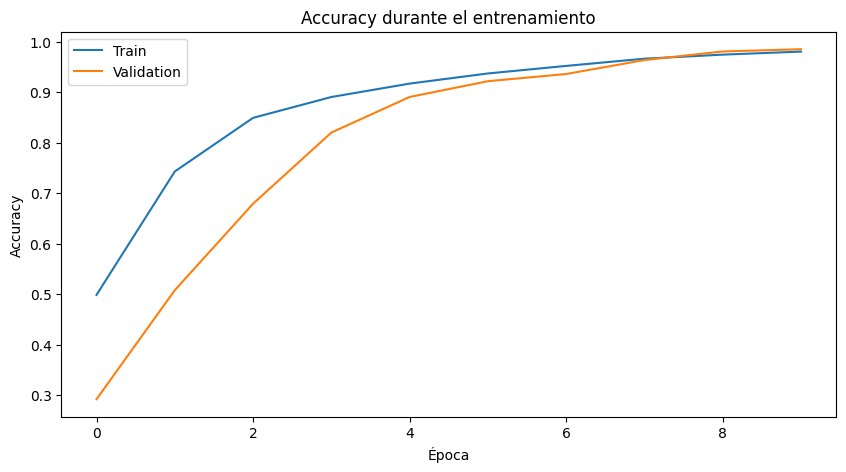

Train accuracy:
[0.49832627177238464, 0.7426913380622864, 0.8489176630973816, 0.890203058719635, 0.9167596697807312, 0.9368444681167603, 0.9517964720726013, 0.9660789966583252, 0.9741129279136658, 0.98013836145401]

Validation accuracy:
[0.29170385003089905, 0.5075825452804565, 0.6788581609725952, 0.819803774356842, 0.8902765512466431, 0.9214986562728882, 0.935771644115448, 0.9634255170822144, 0.9803746938705444, 0.9848349690437317]


In [21]:
plt.figure(figsize=(10, 5))
plt.plot(h.history["accuracy"], label="Train")
plt.plot(h.history["val_accuracy"], label="Validation")
plt.title("Accuracy durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

print("Train accuracy:")
print(h.history["accuracy"])

print("\nValidation accuracy:")
print(h.history["val_accuracy"])

### Evolución de la accuracy durante el entrenamiento

Grafica dos líneas usando el historial de entrenamiento (h.history): la accuracy en el set de entrenamiento y la accuracy en el set de validación, una por cada una de las 10 épocas.

Es el gráfico más importante para diagnosticar cómo aprendió el modelo. Se debe explicar:
- Ambas curvas suben de forma sostenida -> el modelo efectivamente está aprendiendo.
- La curva de validación sigue de cerca a la de entrenamiento (llegan a ~0.98 y ~0.985) → no hay sobreajuste evidente. Si la curva de train siguiera subiendo pero la de validación se estancara o bajara, eso sería señal de overfitting (el modelo "memoriza" el train pero no generaliza).
- Ambas curvas siguen subiendo hasta la última época -> sugiere que con más épocas el modelo probablemente seguiría mejorando un poco más.

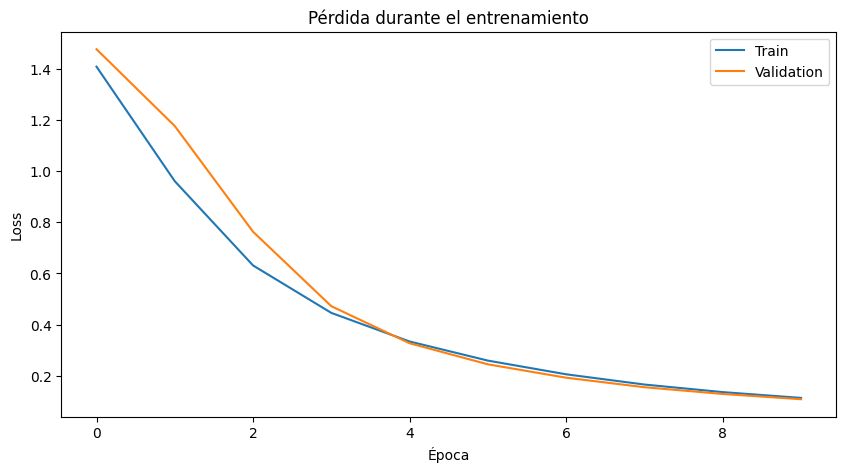

In [22]:
plt.figure(figsize=(10, 5))
plt.plot(h.history["loss"], label="Train")
plt.plot(h.history["val_loss"], label="Validation")
plt.title("Pérdida durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Evolución de la función de pérdida (loss) durante el entrenamiento

Igual que el gráfico anterior, pero grafica el valor de la función de pérdida (categorical_crossentropy) en train y validación por época.

Complementa la curva de accuracy. Mientras la accuracy mide "cuántos aciertos", la pérdida mide "qué tan confiadas y correctas son las predicciones" de forma más fina. Se debe explicar que ambas curvas bajan de forma consistente y sin oscilaciones bruscas, lo que indica que el optimizador (SGD) está convergiendo correctamente. Si la pérdida de validación empezara a subir mientras la de train sigue bajando, sería otra señal clásica de sobreajuste — que aquí no ocurre.

# 7. Evaluación y Métricas

Evaluación final sobre TEST

La evaluación se realiza exclusivamente sobre las cinco vocales seleccionadas.

In [23]:
test_loss, test_accuracy = red.evaluate(
    X_test,
    y_test_one_hot,
    verbose=0
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test loss: 0.2080
Test accuracy: 0.9343


Al evaluar sobre el conjunto de test (nunca visto durante el entrenamiento), el modelo obtiene un 93.4% de accuracy. Es un poco menor que la accuracy de validación (98.5%), lo cual es esperable, pero sigue siendo un desempeño sólido para el problema planteado.

In [24]:
# Predicciones
y_prob = red.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Primeras 20 etiquetas reales:", y_test[:20])
print("Primeras 20 predicciones:", y_pred[:20])

Primeras 20 etiquetas reales: [0 3 2 2 1 0 0 1 2 3 2 3 1 4 4 1 1 1 4 1]
Primeras 20 predicciones: [0 3 2 2 1 0 0 1 2 3 2 3 1 4 4 1 1 1 4 1]


In [25]:
# Métricas globales
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

metricas = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision macro", "Recall macro", "F1 macro"],
    "Valor": [accuracy, precision, recall, f1]
})

metricas

,Métrica,Valor
0,Accuracy,0.934316
1,Precision macro,0.937394
2,Recall macro,0.919354
3,F1 macro,0.922578


Las clases con menor recall fueron O (0.776) e I (0.826), mientras que A y E superan 0.99 de recall. Esto es consistente con que O, I y U son señas con formas de mano más similares entre sí (formas cerradas/redondeadas), lo que dificulta que un modelo sin percepción espacial (como un MLP) las distinga bien.

In [26]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           A     0.9620    0.9940    0.9777       331
           E     0.9595    1.0000    0.9794       498
           I     0.9597    0.8264    0.8881       288
           O     0.9948    0.7764    0.8721       246
           U     0.8110    1.0000    0.8956       266

    accuracy                         0.9343      1629
   macro avg     0.9374    0.9194    0.9226      1629
weighted avg     0.9411    0.9343    0.9330      1629



El reporte por clase muestra que A y E tienen un recall casi perfecto (>0.99), mientras que O (0.776) e I (0.826) presentan más errores. Esto sugiere que el modelo confunde más estas señas, probablemente porque tienen formas de mano visualmente más parecidas entre sí que A o E.

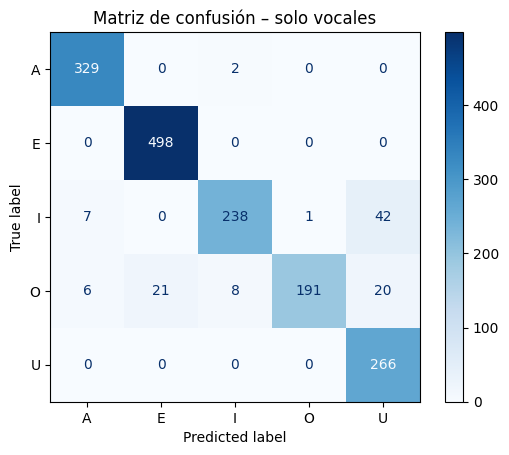

In [27]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(NUM_CLASSES))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión – solo vocales")
plt.show()

### Matriz de confusión

Con las predicciones del modelo sobre el conjunto de test (y_pred) y las etiquetas reales (y_test), se construye una matriz de 5x5 (confusion_matrix) donde cada celda [i,j] indica cuántas imágenes de la clase real "i" fueron clasificadas como la clase j. Se visualiza con ConfusionMatrixDisplay.

Es el gráfico que muestra el detalle que las métricas globales (accuracy, F1) no muestran exactamente con qué clase se confunde cada vocal. La diagonal principal son los aciertos; todo lo que está fuera de la diagonal son errores.

Al presentar, hay que señalar directamente sobre el gráfico la celda fuera de la diagonal con el número más alto (probablemente entre O e I, o entre O y U, dado que O tuvo el recall más bajo, 0.776) y explicar que esa confusión ocurre porque esas señas tienen formas de mano visualmente parecidas, y el MLP al no captar relaciones espaciales, solo intensidades de píxeles aplanadas y no logra distinguir bien esos matices finos de forma.

Aciertos en TEST: 1522 de 1629
Errores en TEST: 107 de 1629


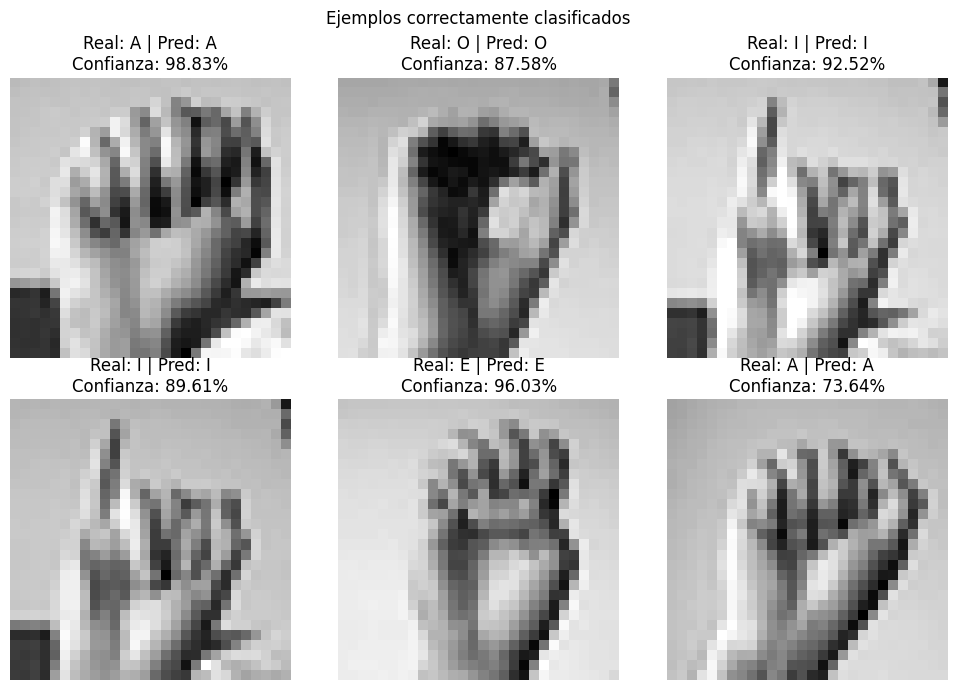

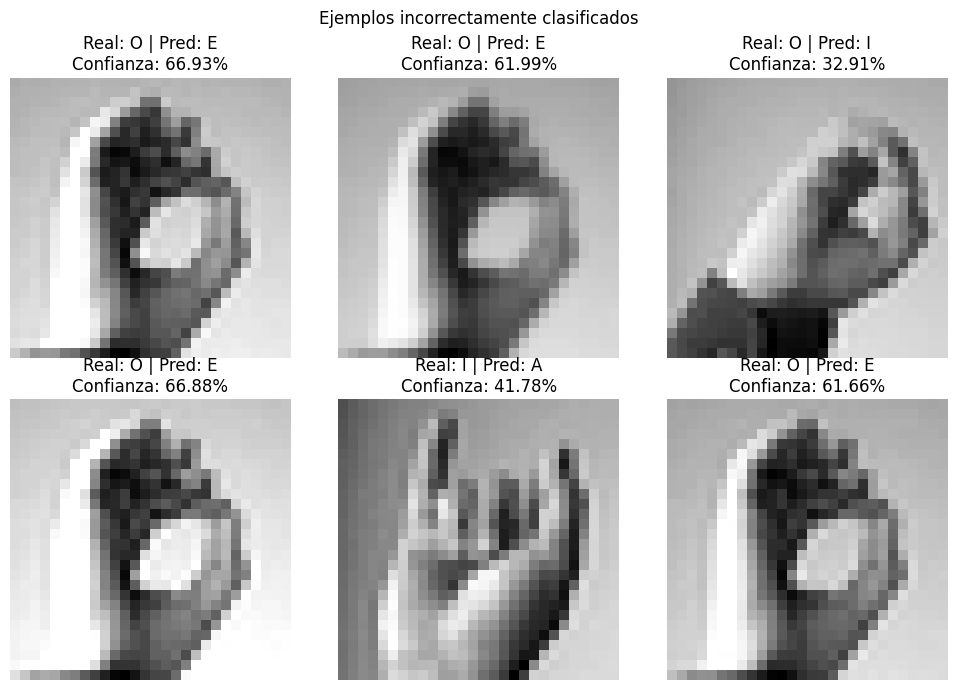


Principales confusiones (real -> predicha):
I -> U: 42 casos
O -> E: 21 casos
O -> U: 20 casos
O -> I: 8 casos
I -> A: 7 casos


In [28]:
# Auditoría explícita de aciertos y errores sobre TEST.
# Se seleccionan obligatoriamente ejemplos de ambas categorías para cumplir la rúbrica.
aciertos = np.where(y_test == y_pred)[0]
errores = np.where(y_test != y_pred)[0]

print(f"Aciertos en TEST: {len(aciertos)} de {len(y_test)}")
print(f"Errores en TEST: {len(errores)} de {len(y_test)}")

# 6 aciertos + 6 errores (siempre que existan suficientes ejemplos)
n_ok = min(6, len(aciertos))
n_err = min(6, len(errores))
indices_ok = aciertos[:n_ok]
indices_err = errores[:n_err]

def mostrar_auditoria(indices, titulo):
    if len(indices) == 0:
        print(f"No hay ejemplos disponibles para: {titulo}")
        return
    cols = 3
    rows = int(np.ceil(len(indices) / cols))
    plt.figure(figsize=(10, 3.5 * rows))
    for pos, idx in enumerate(indices, start=1):
        plt.subplot(rows, cols, pos)
        plt.imshow(X_test[idx].squeeze(), cmap="gray")
        real = class_names[y_test[idx]]
        pred = class_names[y_pred[idx]]
        confianza = y_prob[idx][y_pred[idx]]
        plt.title(f"Real: {real} | Pred: {pred}\nConfianza: {confianza:.2%}")
        plt.axis("off")
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()

mostrar_auditoria(indices_ok, "Ejemplos correctamente clasificados")
mostrar_auditoria(indices_err, "Ejemplos incorrectamente clasificados")

# Identificar las principales confusiones fuera de la diagonal.
cm_sin_diag = cm.copy()
np.fill_diagonal(cm_sin_diag, 0)
pares_confusion = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm_sin_diag[i, j] > 0:
            pares_confusion.append((cm_sin_diag[i, j], class_names[i], class_names[j]))

pares_confusion = sorted(pares_confusion, reverse=True)
print("\nPrincipales confusiones (real -> predicha):")
for cantidad, real, pred in pares_confusion[:5]:
    print(f"{real} -> {pred}: {cantidad} casos")


### Auditoría de aciertos y errores

El notebook selecciona de forma explícita ejemplos correctamente e incorrectamente clasificados para que ambos casos queden evidenciados. Además, se muestran las principales confusiones entre vocales calculadas directamente desde la matriz de confusión. Esto permite relacionar las métricas globales con casos concretos y justificar las limitaciones observadas.


### Limitaciones del uso de un MLP para clasificación de imágenes

Aunque el modelo alcanzó un buen desempeño (93.4% de accuracy), un Perceptrón Multicapa tiene limitaciones importantes para trabajar con imágenes:

- **Pérdida de la estructura espacial:** la capa `Flatten` convierte la imagen 28×28 en un vector de 784 valores, eliminando la relación de vecindad entre píxeles. El modelo no "sabe" que dos píxeles están uno al lado del otro.
- **Sensibilidad a variaciones de posición:** si la mano en la imagen estuviera desplazada, rotada o en otra escala, el modelo tendría dificultades para reconocerla, porque no tiene mecanismos de invarianza espacial (a diferencia de una CNN, que sí los tiene mediante convoluciones y pooling).
- **Número de parámetros elevado:** al conectar cada píxel con cada neurona de la primera capa densa, el modelo usa muchos parámetros solo para procesar la entrada, lo que puede llevar a sobreajuste en datasets más pequeños o con imágenes más grandes.
- **Confusión entre clases visualmente similares:** esto se refleja en los resultados: las vocales **O** (recall 0.776) e **I** (recall 0.826) presentan más errores, probablemente porque sus señas tienen formas de mano parecidas a la de U, y el MLP no logra capturar los detalles finos que distinguen estas formas.

Una mejora natural para las siguientes experiencias de aprendizaje sería reemplazar este MLP por una **red convolucional (CNN)**, que sí preserva la estructura espacial de la imagen y suele obtener mejor desempeño en tareas de visión computacional.

### Demostración de Inferencia

Función de predicción para una imagen **28×28**

La función recibe una matriz con **784** píxeles o una imagen ya formada en **28×28** y devuelve la vocal predicha.

In [29]:
def predecir_vocal(imagen):
    imagen = np.asarray(imagen, dtype="float32")

    if imagen.size != 28 * 28:
        raise ValueError("La imagen debe contener exactamente 784 píxeles (28x28).")

    imagen = imagen.reshape(1, 28, 28, 1)
    if imagen.max() > 1.0:
        imagen = imagen / 255.0

    prob = red.predict(imagen, verbose=0)[0]
    idx = int(np.argmax(prob))

    return {
        "vocal_predicha": class_names[idx],
        "probabilidad": float(prob[idx]),
        "probabilidades": dict(zip(class_names, prob.tolist()))
    }

# Ejemplo con la primera imagen del test
resultado = predecir_vocal(X_test[0])
resultado

{'vocal_predicha': 'A',
 'probabilidad': 0.9882521033287048,
 'probabilidades': {'A': 0.9882521033287048,
  'E': 0.010770685039460659,
  'I': 0.0009768283925950527,
  'O': 3.7064714319967607e-07,
  'U': 2.0924725063764527e-08}}

# 8. Conclusiones y Análisis

- El modelo MLP implementado logró un desempeño sólido para el problema acotado de clasificar 5 vocales del lenguaje de señas, alcanzando 93.4% de accuracy, 0.937 de precision macro y 0.923 de F1-score macro en el conjunto de test.
- Las decisiones de diseño (arquitectura 128->64->5, SGD, categorical_crossentropy, 10 épocas) resultaron adecuadas para este problema acotado, logrando convergencia estable sin señales evidentes de sobreajuste.
- Las principales debilidades del modelo se concentran en las clases O e I, que se confunden más entre sí por la similitud visual de las señas correspondientes.
- La principal limitación del enfoque es estructural: un MLP no aprovecha la información espacial de la imagen, lo que abre la puerta a mejoras futuras mediante una arquitectura CNN.
- Como próximos pasos, se propone: 1.- extender el problema a las 24 letras completas del dataset,
2.- comparar el MLP contra una CNN simple,
3.- explorar técnicas de data augmentation para reducir la confusión entre clases similares.